# Logistic regression with Python

## Case study with quality of healthcare

### Exploration: Data import and exploration

In [1]:
import pandas as pd
import numpy as np

In [2]:
data_path = r"C:\Users\moeka\Downloads\Quality.csv"
# Read the CSV file
quality_df = pd.read_csv(data_path)
# Display the first few rows of the DataFrame
quality_df.head()

,MemberID,ERVisits,OfficeVisits,Narcotics,ProviderCount,NumberClaims,StartedOnCombination,PoorCare
0,1,0,18,1,21,93,False,0
1,2,1,6,1,27,19,False,0
2,3,0,5,3,16,27,False,0
3,4,1,19,0,14,59,False,0
4,5,2,19,3,24,51,False,0


In [3]:
quality_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   MemberID              131 non-null    int64
 1   ERVisits              131 non-null    int64
 2   OfficeVisits          131 non-null    int64
 3   Narcotics             131 non-null    int64
 4   ProviderCount         131 non-null    int64
 5   NumberClaims          131 non-null    int64
 6   StartedOnCombination  131 non-null    bool 
 7   PoorCare              131 non-null    int64
dtypes: bool(1), int64(7)
memory usage: 7.4 KB


**MemberID**: A unique identifier for each observation. This variable is categorical and used for identification purposes only.

**ERVisits**: The number of times the patient visited the emergency room. A higher number might suggest poor management of chronic conditions or lack of access to primary care, potentially indicating lower quality of care.

**OfficeVisits**: The number of times the patient visited any doctor's office. Frequent visits could be associated with better management of health conditions, while very few visits may indicate potential neglect of regular check-ups or preventive care.

**Narcotics**: The number of prescriptions the patient had for narcotics. While a high count may be necessary for certain health conditions or pain management, it could also signal potential over-prescription or misuse of medication.

**ProviderCount**: The number of providers that saw or treated the patient. A high count could imply fragmented care or poor care coordination, which might lead to lower quality of care. Conversely, a low count might suggest better continuity of care.

**NumberClaims**: The total number of medical claims the patient had. An elevated number of claims could indicate extensive use of healthcare services, which may be due to complex health conditions or, in some cases, unnecessary services.

**StartedOnCombination**: Whether or not the patient was started on a combination of drugs to treat their diabetes. Starting on a combination may reflect a more aggressive treatment approach, which could be appropriate for certain clinical scenarios.

**PoorCare**: Whether or not the patient received poor care (1 if the patient had poor care, 0 otherwise). This is a binary outcome variable, likely used as a response variable in quality of care analyses.

In [4]:
#count unique values in variable StartedOnCombination
print(quality_df['StartedOnCombination'].value_counts())
#count unique values in variable PoorCare
print(quality_df['PoorCare'].value_counts())

StartedOnCombination
False    125
True       6
Name: count, dtype: int64
PoorCare
0    98
1    33
Name: count, dtype: int64


In [5]:
# Convert the 'StartedOnCombination' column to a categorical type using sklearn
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder(categories=[[False, True]])
quality_df['StartedOnCombination_oe'] = oe.fit_transform(quality_df[['StartedOnCombination']])

In [6]:
quality_df

,MemberID,ERVisits,OfficeVisits,Narcotics,ProviderCount,NumberClaims,StartedOnCombination,PoorCare,StartedOnCombination_oe
0,1,0,18,1,21,93,False,0,0.0
1,2,1,6,1,27,19,False,0,0.0
2,3,0,5,3,16,27,False,0,0.0
3,4,1,19,0,14,59,False,0,0.0
4,5,2,19,3,24,51,False,0,0.0
...,...,...,...,...,...,...,...,...,...
126,127,1,5,3,11,11,False,0,0.0
127,128,0,3,2,35,18,False,0,0.0
128,129,11,5,9,56,43,False,0,0.0
129,130,2,14,1,26,41,False,1,0.0


Now we can plot the distribution of each variable.


In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style of seaborn
sns.set_style(style="whitegrid")  

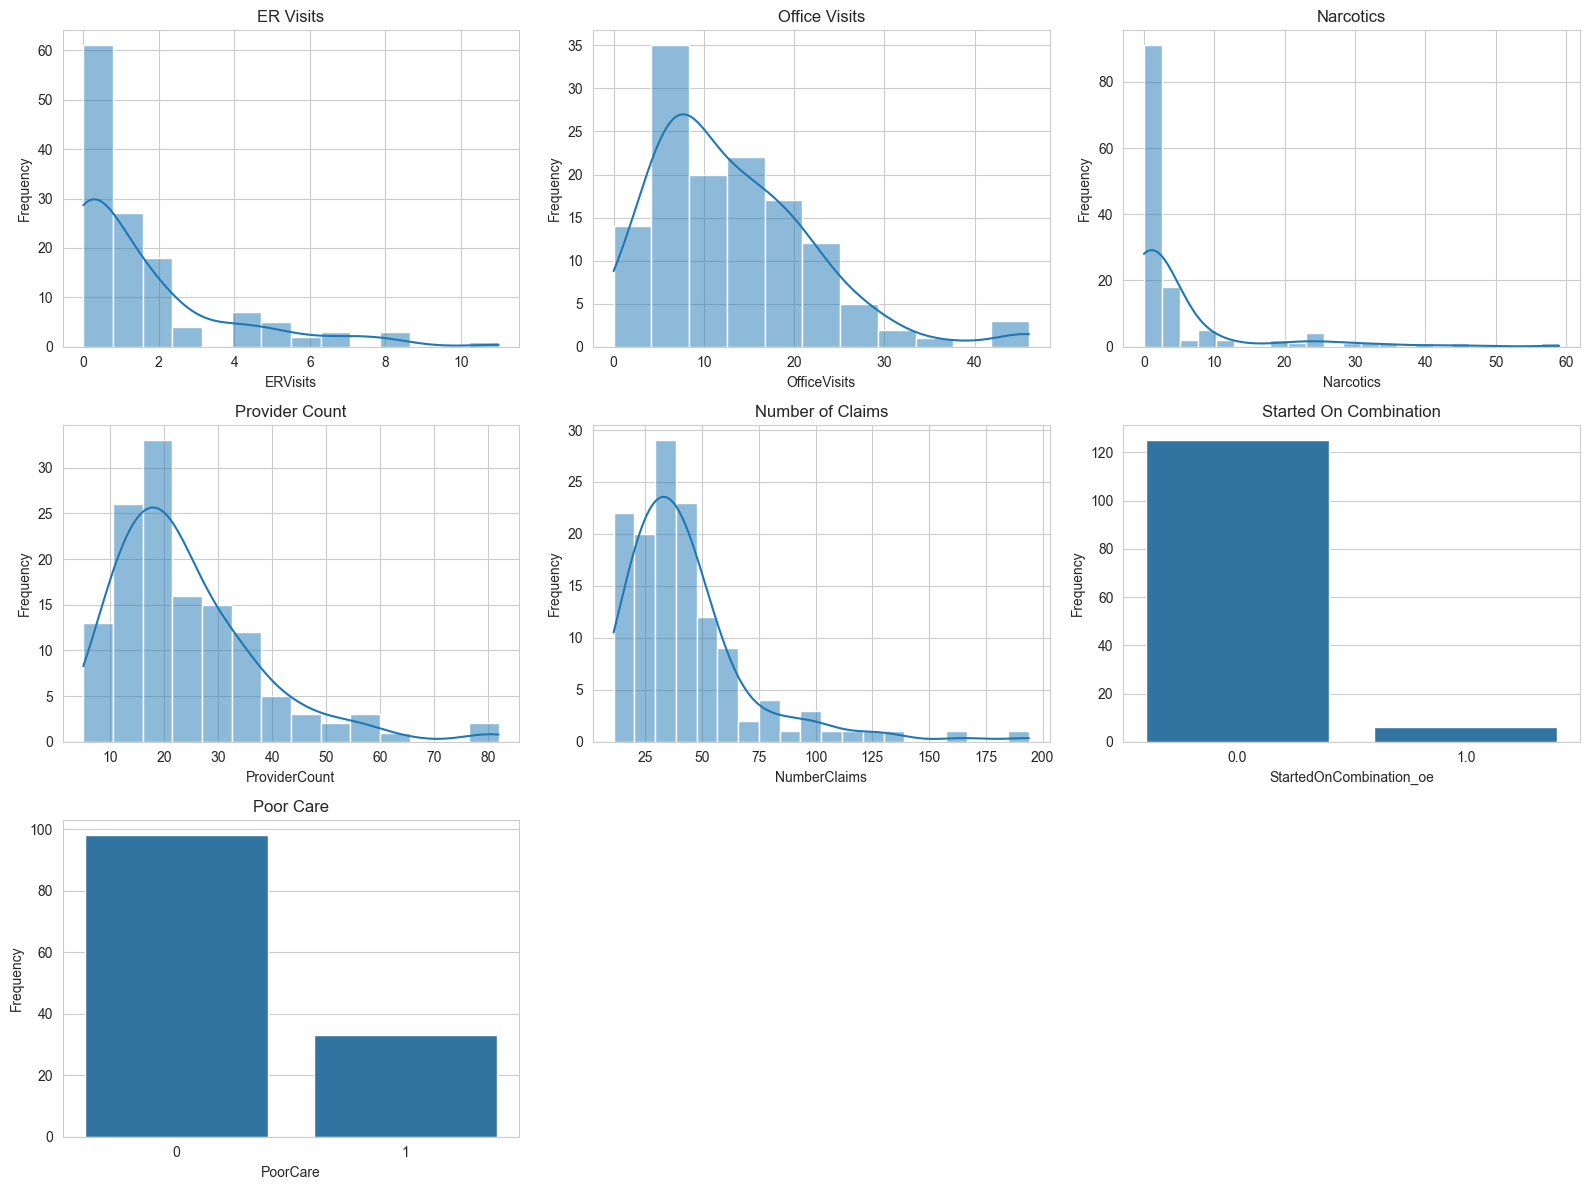

In [8]:
# Create a figure and axes for subplots
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()  # Flatten the axes array for easier indexing

# Create a list of columns to plot
columns_to_plot = [
    "ERVisits", "OfficeVisits", "Narcotics", 
    "ProviderCount", "NumberClaims",
    'StartedOnCombination_oe', 'PoorCare',
]
# Create a list of titles for the subplots
titles = [
    "ER Visits", "Office Visits", "Narcotics",
    "Provider Count", "Number of Claims",
    'Started On Combination', 'Poor Care',
]

# create a historgram for each column using a for loop if the column is numeric
for i, col in enumerate(columns_to_plot):
    
    if col in ["StartedOnCombination_oe", 'PoorCare']:
        # create a count plot for the categorical columns
        sns.countplot(data = quality_df, x = col, ax=axes[i])
    else: 
        # Create a histogram for the current column
        sns.histplot(data = quality_df, x = col, kde=True, ax=axes[i])
    
    # Set the title and labels
    axes[i].set_title(titles[i])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency') 

# delete the last two axes since we have only 7 plots
fig.delaxes(axes[-2])
fig.delaxes(axes[-1])


# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

### Split the data 

In [9]:
# Split the data into train and test sets
from sklearn.model_selection import train_test_split

# create df_Train and df_Test
## randomly split the dataset into training set: 75%, and testing set: 25%
train_df, test_df = train_test_split(quality_df, test_size=0.25, random_state=42)   

# print the shape of the train and test sets
print(f"Train set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")

Train set shape: (98, 9)
Test set shape: (33, 9)


In [10]:
# Create summary statistics for the training set
train_summary = train_df.describe(include='all')        
# Display the summary statistics    
train_summary

,MemberID,ERVisits,OfficeVisits,Narcotics,ProviderCount,NumberClaims,StartedOnCombination,PoorCare,StartedOnCombination_oe
count,98.000000,98.000000,98.000000,98.000000,98.000000,98.000000,98,98.000000,98.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,94,NaN,NaN
mean,68.397959,1.459184,12.765306,4.928571,24.989796,44.581633,NaN,0.255102,0.040816
std,38.308229,2.183199,8.442408,9.318256,14.047412,30.105630,NaN,0.438160,0.198882
min,2.000000,0.000000,0.000000,0.000000,5.000000,11.000000,NaN,0.000000,0.000000
25%,35.250000,0.000000,7.000000,0.000000,15.000000,27.000000,NaN,0.000000,0.000000
50%,68.500000,1.000000,10.000000,1.000000,21.000000,37.000000,NaN,0.000000,0.000000
75%,102.750000,2.000000,18.000000,3.000000,31.750000,49.750000,NaN,0.750000,0.000000


### Model Training with the statsmodels.fomula

In [11]:
import statsmodels.formula.api as smf
# Fit a logistic regression model using the training set
logit_model = smf.logit('PoorCare ~ ERVisits + OfficeVisits + Narcotics + ProviderCount + NumberClaims + StartedOnCombination_oe', data=train_df)
# Fit the model
logit_model_fit = logit_model.fit()
# Print the summary of the model    
print(logit_model_fit.summary())

Optimization terminated successfully.
         Current function value: 0.403369
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:               PoorCare   No. Observations:                   98
Model:                          Logit   Df Residuals:                       91
Method:                           MLE   Df Model:                            6
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                  0.2897
Time:                        08:42:45   Log-Likelihood:                -39.530
converged:                       True   LL-Null:                       -55.651
Covariance Type:            nonrobust   LLR p-value:                 1.466e-05
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -3.5278      0.862     -4.091      0.000      -5.218   

In [12]:
# Predict probability of poor care for each patient in the training set
# use 0.5 as threshold to classify patient into good care or poor care

# save the predictions back to df_train
train_df['Predicted_Prob'] = logit_model_fit.predict(train_df)
# create a new column 'Predicted_Class' based on the threshold
train_df['Predicted_Class'] = np.where(train_df['Predicted_Prob'] > 0.5, 1, 0) # equivalent as # df_train['PoorCare_pred'] = (train_df['Predicted_Prob'] > 0.5 ).astype(int)

In [13]:
train_df.head()

,MemberID,ERVisits,OfficeVisits,Narcotics,ProviderCount,NumberClaims,StartedOnCombination,PoorCare,StartedOnCombination_oe,Predicted_Prob,Predicted_Class
24,25,0,14,1,18,33,False,0,0.0,0.123683,0
67,68,0,9,2,15,21,False,0,0.0,0.096080,0
113,114,0,14,25,14,31,False,1,0.0,0.631894,1
89,90,1,0,0,7,19,False,0,0.0,0.033883,0
15,16,0,8,0,5,19,False,0,0.0,0.052653,0


In [14]:
# create a confusion matrix using crosstab
train_confusion_matrix = pd.crosstab(train_df['PoorCare'], train_df['Predicted_Class'], rownames=['Actual'], colnames=['Predicted'])

In [15]:
train_confusion_matrix

Predicted,0,1
Actual,,
0,69,4
1,12,13


In [16]:
# Create confusion matrix using sklearn
from sklearn.metrics import confusion_matrix
# create confusion matrix
cm = confusion_matrix(train_df['PoorCare'], train_df['Predicted_Class'])
cm

array([[69,  4],
       [12, 13]])

In [17]:
# Calcualte training accuracy using sklearn
from sklearn.metrics import accuracy_score
# calculate accuracy    
train_accuracy = accuracy_score(train_df['PoorCare'], train_df['Predicted_Class'])
print(f"Training Accuracy: {train_accuracy:.2f}")

Training Accuracy: 0.84


### Predicting on the test set

In [18]:
# predict probability of poor care for each patient in the test set
test_df['Predicted_Prob'] = logit_model_fit.predict(test_df)
# create a new column 'Predicted_Class' based on the threshold
test_df['Predicted_Class'] = np.where(test_df['Predicted_Prob'] > 0.5, 1, 0) # equivalent as # df_test['PoorCare_pred'] = (test_df['Predicted_Prob'] > 0.5 ).astype(int)
test_df.head()

,MemberID,ERVisits,OfficeVisits,Narcotics,ProviderCount,NumberClaims,StartedOnCombination,PoorCare,StartedOnCombination_oe,Predicted_Prob,Predicted_Class
55,56,7,46,0,18,78,True,1,1.0,0.901138,1
40,41,0,15,0,11,38,True,1,1.0,0.461545,0
19,20,1,20,0,27,53,False,0,0.0,0.197274,0
31,32,4,45,0,63,133,False,0,0.0,0.785903,1
115,116,4,10,1,11,38,False,0,0.0,0.080928,0


In [19]:
# Calcualte the test_confusion_matrix using sklearn
from sklearn.metrics import confusion_matrix
# create confusion matrix sklern
test_confusion_matrix = confusion_matrix(test_df['PoorCare'], test_df['Predicted_Class'])
test_confusion_matrix

array([[24,  1],
       [ 5,  3]])

In [20]:
# Calcualte test accuracy
test_accuracy = accuracy_score(test_df['PoorCare'], test_df['Predicted_Class'])
print(f"Test Accuracy: {test_accuracy:.2f}")

Test Accuracy: 0.82


### Changing the threshold

In [21]:
# Create a new Predicted class column in the training set
threshold = 0.1
train_df['Predicted_Class_01'] = np.where(train_df['Predicted_Prob'] > threshold, 1, 0) # equivalent as # df_train['PoorCare_pred'] = (train_df['Predicted_Prob'] > 0.5 ).astype(int)

cm_train_01 = confusion_matrix(train_df['PoorCare'], train_df['Predicted_Class_01'])
print(cm_train_01)
# Calcualte training accuracy using sklearn
accuracy_train_01 = accuracy_score(train_df['PoorCare'], train_df['Predicted_Class_01'])
print(f"Training Accuracy with threshold {threshold}: {accuracy_train_01:.2f}")

[[34 39]
 [ 0 25]]
Training Accuracy with threshold 0.1: 0.60


The model makes more "1" predictions with a low threhold and only predict one "1" as "0"s, but makes a lot of errors predicting "0"s as "1"s

In [22]:
# Create a new Predicted class column in the training set
threshold = 0.9
train_df['Predicted_Class_09'] = np.where(train_df['Predicted_Prob'] > threshold, 1, 0) # equivalent as # train_df['PoorCare_pred'] = (train_df['Predicted_Prob'] > 0.5 ).astype(int)

cm_train_09 = confusion_matrix(train_df['PoorCare'], train_df['Predicted_Class_09'])
print(cm_train_09)
# Calcualte training accuracy using sklearn
accuracy_train_09 = accuracy_score(train_df['PoorCare'], train_df['Predicted_Class_09'])
print(f"Training Accuracy with threshold {threshold}: {accuracy_train_09:.2f}")

[[72  1]
 [22  3]]
Training Accuracy with threshold 0.9: 0.77


The model makes less "1" predictions with a high threhold and does not predict any "0" as "1"s, but makes a lot of errors predicting "1"s as "0"s

### Model Evaluations Summary: Accuracy, Precision, and Recall, f1

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# Calculate the accuracy, precision, recall, and F1 score for the training set
train_accuracy = accuracy_score(train_df['PoorCare'], train_df['Predicted_Class'])      
train_precision = precision_score(train_df['PoorCare'], train_df['Predicted_Class'])
train_recall = recall_score(train_df['PoorCare'], train_df['Predicted_Class'])          
train_f1 = f1_score(train_df['PoorCare'], train_df['Predicted_Class'])
# Print the evaluation metrics
print(f"Training Accuracy: {train_accuracy:.2f}")       
print(f"Training Precision: {train_precision:.2f}")
print(f"Training Recall: {train_recall:.2f}")   
print(f"Training F1 Score: {train_f1:.2f}")
# Calculate the accuracy, precision, recall, and F1 score for the test set
test_accuracy = accuracy_score(test_df['PoorCare'], test_df['Predicted_Class'])         
test_precision = precision_score(test_df['PoorCare'], test_df['Predicted_Class'])
test_recall = recall_score(test_df['PoorCare'], test_df['Predicted_Class'])
test_f1 = f1_score(test_df['PoorCare'], test_df['Predicted_Class'])

# Print the evaluation metrics
print(f"Test Accuracy: {test_accuracy:.2f}")            
print(f"Test Precision: {test_precision:.2f}")
print(f"Test Recall: {test_recall:.2f}")
print(f"Test F1 Score: {test_f1:.2f}")

Training Accuracy: 0.84
Training Precision: 0.76
Training Recall: 0.52
Training F1 Score: 0.62
Test Accuracy: 0.82
Test Precision: 0.75
Test Recall: 0.38
Test F1 Score: 0.50


### AUC scores

In [24]:
train_df.head()

,MemberID,ERVisits,OfficeVisits,Narcotics,ProviderCount,NumberClaims,StartedOnCombination,PoorCare,StartedOnCombination_oe,Predicted_Prob,Predicted_Class,Predicted_Class_01,Predicted_Class_09
24,25,0,14,1,18,33,False,0,0.0,0.123683,0,1,0
67,68,0,9,2,15,21,False,0,0.0,0.096080,0,0,0
113,114,0,14,25,14,31,False,1,0.0,0.631894,1,1,0
89,90,1,0,0,7,19,False,0,0.0,0.033883,0,0,0
15,16,0,8,0,5,19,False,0,0.0,0.052653,0,0,0


In [25]:
# Calcualte the AUC for the training set
from sklearn.metrics import roc_auc_score
# Calculate the AUC for the training set
auc_train = roc_auc_score(train_df['PoorCare'], train_df['Predicted_Prob'])
print(f"Training AUC: {auc_train:.2f}")

Training AUC: 0.87


In [26]:
# Calculate the AUC for the test set
auc_test = roc_auc_score(test_df['PoorCare'], test_df['Predicted_Prob'])    
print(f"Test AUC: {auc_test:.2f}")

Test AUC: 0.65


Plot the ROC curve.

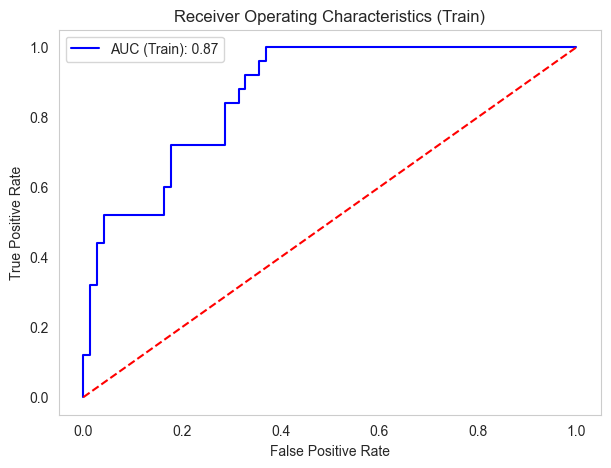

In [27]:
# Plot the ROC curve for the training set
from sklearn.metrics import roc_curve
# Calculate the ROC curve
fpr_train, tpr_train, thresholds_train = roc_curve(train_df['PoorCare'], train_df['Predicted_Prob'])
# Plot the ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr_train, tpr_train, label=f'AUC (Train): {auc_train:.2f}', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='red')  # Diagonal line
plt.title('Receiver Operating Characteristics (Train)')  
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')    
plt.legend()
plt.grid()  
plt.show()

### Exercise: Improve the model

Play with the variables and the code below to try to build a reliable model with good metrics on the test set. Remove some highly correlated variables (if any) and the non-significant variables one by one. Looking into the correlation matrix is optional.

Keep in mind that it's possible that despite trying different variable combinations and hyperparameter value, the model's performance may not improve. This can happen due to various reasons, such as the inherent complexity of the problem, limitations of the available features, or the presence of noise in the data. So no worries :)

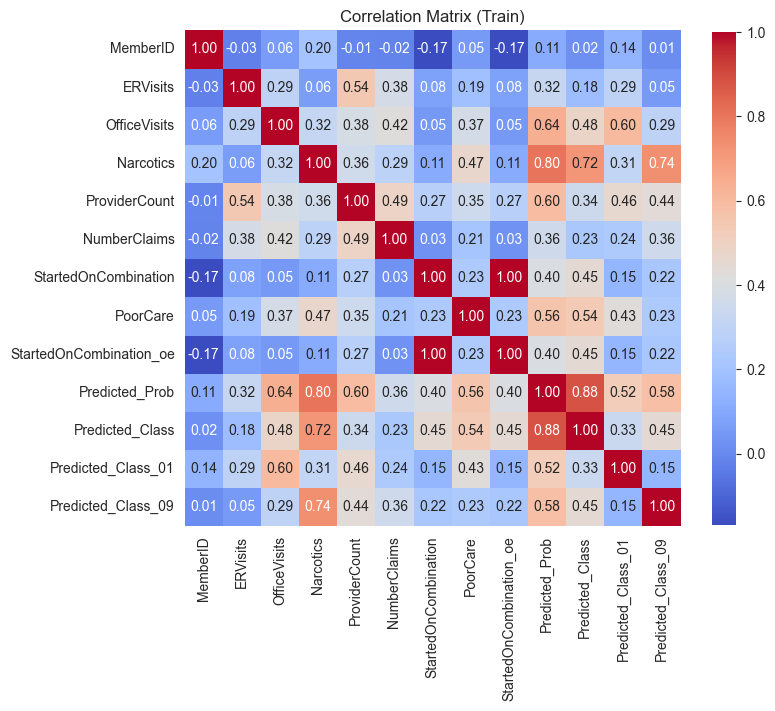

In [28]:
# Calculate the train set correlation matrix
corr_train = train_df.corr()

# Plot the correlation matrix with heatmap
plt.figure(figsize=(8, 8))
sns.heatmap(corr_train, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={"shrink": .8})   
plt.title('Correlation Matrix (Train)')
plt.show()

In [29]:
import statsmodels.formula.api as smf
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
# Define a logistic with statsmodels formula.api
lr = smf.logit('PoorCare ~ ERVisits + OfficeVisits + Narcotics + ProviderCount + NumberClaims + StartedOnCombination_oe', data=train_df)    
# Fit the model
res = lr.fit()
# Print the summary of the model
print(res.summary())

y_pred_train = res.predict(train_df)
y_pred_test = res.predict(test_df)

#select threshold
t = 0.5

train_df['PoorCare_pred'] = (res.predict(train_df) > t ).astype(int)

test_df['PoorCare_pred'] = (res.predict(test_df) > t ).astype(int)

# Calculate the accuracy on the training dataset
accuracy_train = accuracy_score(train_df['PoorCare'], train_df['PoorCare_pred'])

# Calculate the precision on the training dataset
precision_train = precision_score(train_df['PoorCare'], train_df['PoorCare_pred'])

# Calculate the recall on the training dataset
recall_train = recall_score(train_df['PoorCare'], train_df['PoorCare_pred'])

# Calculate the AUC on the training dataset
auc_train = roc_auc_score(train_df['PoorCare'], y_pred_train)

# Calculate the accuracy on the testing dataset
accuracy_test = accuracy_score(test_df['PoorCare'], test_df['PoorCare_pred'])

# Calculate the precision on the testing dataset
precision_test = precision_score(test_df['PoorCare'], test_df['PoorCare_pred'])

# Calculate the recall on the testing dataset
recall_test = recall_score(test_df['PoorCare'], test_df['PoorCare_pred'])

# Calculate the AUC on the testing dataset
auc_test = roc_auc_score(test_df['PoorCare'], y_pred_test)

print("Threshold is:", t, "\n")
print("Training Dataset Metrics:")
print("  Accuracy:  {:.2f}".format(accuracy_train))
print("  Precision: {:.2f}".format(precision_train))
print("  Recall:    {:.2f}".format(recall_train))
print("  AUC:       {:.2f}".format(auc_train))
print()
print("Testing Dataset Metrics:")
print("  Accuracy:  {:.2f}".format(accuracy_test))
print("  Precision: {:.2f}".format(precision_test))
print("  Recall:    {:.2f}".format(recall_test))
print("  AUC:       {:.2f}".format(auc_test))

Optimization terminated successfully.
         Current function value: 0.403369
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:               PoorCare   No. Observations:                   98
Model:                          Logit   Df Residuals:                       91
Method:                           MLE   Df Model:                            6
Date:                Wed, 30 Sep 2026   Pseudo R-squ.:                  0.2897
Time:                        08:42:45   Log-Likelihood:                -39.530
converged:                       True   LL-Null:                       -55.651
Covariance Type:            nonrobust   LLR p-value:                 1.466e-05
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -3.5278      0.862     -4.091      0.000      -5.218   